# PLL loop-filter design (SymPy)

Run with the project's `.venv` (set up from `requirements.txt` at the repo root):

```bash
python3 -m venv .venv
.venv/bin/pip install -r requirements.txt
.venv/bin/jupyter lab doc/pll-filter/pll-filter.ipynb
```


In [113]:
import sympy as sp
from IPython.display import display, Math
from matplotlib.ticker import EngFormatter
eng = EngFormatter(places=3, sep=' ')

sp.init_printing()
pi = sp.pi
j = sp.I
s = sp.symbols('s')

def par(Za, Zb):
    return sp.simplify(Za * Zb / (Za + Zb))

## Design equations

In [122]:
# Input params
f_ref_MHz = 5
chp_current_uA = 5
vco_gain_MHz_per_V = 226
div_ratio = 20

# Design constants
Kp = sp.Rational(chp_current_uA, 10**6) / (2 * pi)
Kv = sp.Integer(2 * pi * vco_gain_MHz_per_V) * 10**6  
N = sp.Integer(div_ratio)
f_ug_target = sp.Integer(f_ref_MHz) * 10**6 / 15   

# Component sizing
CF = sp.simplify(Kp * Kv / (N * (2 * pi * f_ug_target)**2))  # Reference capacitance for target ug freq
C1 = sp.simplify( CF * sp.sqrt(11) / sp.sqrt(131) )
C2 = sp.simplify(10 * C1)
R2 = sp.simplify(sp.sqrt(10) / (2 * pi * C2 * f_ug_target))

# Loop filter and transfer functions
Za = 1 / (s * C1)
Zb = R2 + 1 / (s * C2)
Zf = sp.simplify(par(Za, Zb))

G = sp.simplify(Kp * Zf * (Kv / s))
H = sp.simplify(sp.Integer(1) / N)
G12 = sp.simplify(Kp * (1 / (s * (C1 + C2))) * (Kv / s))
G1 = sp.simplify(Kp * (1 / (s * C1)) * (Kv / s))
Hro = sp.simplify(G / (1 + G * H))

print(f'Kp   = {eng(Kp)}A/rad')
print(f'Kv   = {eng(Kv)}Hz/V')
print(f'N    = {N}')
print(f'fug  = {eng(f_ug_target)}Hz')
print(f'CF   = {eng(float(CF))}F')
print(f'C1   = {eng(float(C1))}F')
print(f'C2   = {eng(float(C2))}F')
print(f'R2   = {eng(float(R2))}Ohm')

# UG frequency and phase margin
w_ug = 2 * pi * f_ug_target
loop_gain_at_ug = sp.simplify(H * G.subs(s, j * w_ug))
loop_gain_db = sp.N(20 * sp.log(sp.Abs(loop_gain_at_ug), 10), 10)
loop_gain_phase_deg = sp.N(sp.arg(loop_gain_at_ug) * 180 / pi, 10)
phase_margin = 180 + loop_gain_phase_deg

display(Math(r'20\log_{10}\left|\frac{1}{N}G(j2\pi f_{ug\_target})\right| = ' + sp.latex(loop_gain_db) + r'\ \mathrm{dB}'))

print(f'f_ug_target                   = {eng(f_ug_target)}Hz')
print(f'20log10(|H*G|) at f_ug_target = {loop_gain_db} dB')
print(f'phase(H*G) at f_ug_target     = {loop_gain_phase_deg} deg')
print(f'phase margin at f_ug_target   = {phase_margin} deg')


Kp   = 795.775 nA/rad
Kv   = 1.419 GHz/V
N    = 20
fug  = 333.333 kHz
CF   = 12.871 pF
C1   = 3.730 pF
C2   = 37.298 pF
R2   = 40.481 kOhm


<IPython.core.display.Math object>

f_ug_target                   = 333.333 kHz
20log10(|H*G|) at f_ug_target = 0 dB
phase(H*G) at f_ug_target     = -123.5872742 deg
phase margin at f_ug_target   = 56.41272577 deg


In [123]:
# Input params
f_ref_MHz = 5
chp_current_uA = 5
vco_gain_MHz_per_V = 226
div_ratio = 20

# Design constants
Kp = sp.Rational(chp_current_uA, 10**6) / (2 * pi)
Kv = sp.Integer(2 * pi * vco_gain_MHz_per_V) * 10**6  
N = sp.Integer(div_ratio)
f_ug_target = sp.Integer(f_ref_MHz) * 10**6 / 20   

# Component values (set in previous section)
"""
C1 = 1.05e-12 * 0.5
C2 = 10.5e-12 * 0.5
R2 = 190e3 * 0.667
"""

# Loop filter and transfer functions
Za = 1 / (s * C1)
Zb = R2 + 1 / (s * C2)
Zf = sp.simplify(par(Za, Zb))

G = sp.simplify(Kp * Zf * (Kv / s))
H = sp.simplify(sp.Integer(1) / N)
G12 = sp.simplify(Kp * (1 / (s * (C1 + C2))) * (Kv / s))
G1 = sp.simplify(Kp * (1 / (s * C1)) * (Kv / s))
Hro = sp.simplify(G / (1 + G * H))

print(f'Kp   = {eng(Kp)}A/rad')
print(f'Kv   = {eng(Kv)}Hz/V')
print(f'N    = {N}')
print(f'fug  = {eng(f_ug_target)}Hz')
print(f'CF   = {eng(float(CF))}F')
print(f'C1   = {eng(float(C1))}F')
print(f'C2   = {eng(float(C2))}F')
print(f'R2   = {eng(float(R2))}Ohm')

# Solve for unity-gain frequency: |H*G(jw)|^2 = 1
# numerator of |H*G|^2 - 1 is a polynomial in w; take its positive real root
w = sp.symbols('omega', positive=True)
LG = H * G.subs(s, j * w)
mag2 = sp.simplify(sp.expand_complex(LG * sp.conjugate(LG)))
num = sp.numer(sp.together(mag2 - 1))
w_ug = [r for r in sp.Poly(num, w).nroots() if r.is_real and r > 0][0]
f_ug = w_ug / (2 * pi)

loop_gain_at_ug = LG.subs(w, w_ug)
loop_gain_db = sp.N(20 * sp.log(sp.Abs(loop_gain_at_ug), 10), 10)
loop_gain_phase_deg = sp.N(sp.arg(loop_gain_at_ug) * 180 / pi, 10)
phase_margin = 180 + loop_gain_phase_deg

print(f'f_ug                   = {eng(float(f_ug))}Hz')
print(f'20log10(|H*G|) at f_ug = {loop_gain_db} dB')
print(f'phase(H*G) at f_ug     = {loop_gain_phase_deg} deg')
print(f'phase margin at f_ug   = {phase_margin} deg')


Kp   = 795.775 nA/rad
Kv   = 1.419 GHz/V
N    = 20
fug  = 250.000 kHz
CF   = 12.871 pF
C1   = 3.730 pF
C2   = 37.298 pF
R2   = 40.481 kOhm
f_ug                   = 333.333 kHz
20log10(|H*G|) at f_ug = 1.827981722E-15 dB
phase(H*G) at f_ug     = -123.5872742 deg
phase margin at f_ug   = 56.41272577 deg


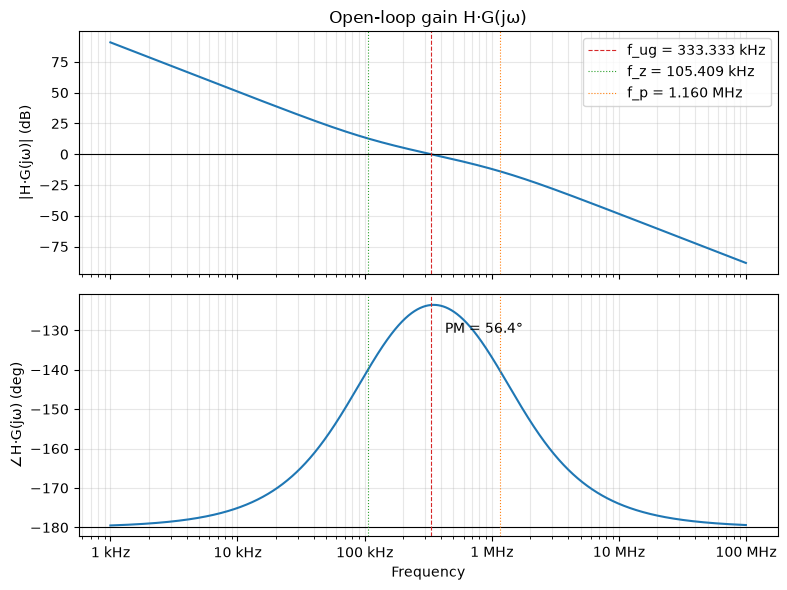

In [124]:
import numpy as np
import matplotlib.pyplot as plt

# Evaluate H*G(jw) numerically over frequency
LG_num = sp.lambdify(w, LG, 'numpy')
f = np.logspace(3, 8, 2001)                          # 1 kHz .. 100 MHz
L = LG_num(2 * np.pi * f)
mag_db = 20 * np.log10(np.abs(L))
phase_deg = np.degrees(np.unwrap(np.angle(L)))

f_u = float(f_ug)
f_z = float(1 / (2 * pi * R2 * C2))                   # zero
f_p = float((C1 + C2) / (2 * pi * R2 * C1 * C2))      # pole

fig, (ax_m, ax_p) = plt.subplots(2, 1, sharex=True, figsize=(8, 6))

ax_m.semilogx(f, mag_db)
ax_m.axhline(0, color='k', lw=0.8)
ax_m.set_ylabel('|H·G(jω)| (dB)')
ax_m.set_title('Open-loop gain H·G(jω)')

ax_p.semilogx(f, phase_deg)
ax_p.axhline(-180, color='k', lw=0.8)
ax_p.set_ylabel('∠H·G(jω) (deg)')
ax_p.set_xlabel('Frequency')
ax_p.xaxis.set_major_formatter(EngFormatter(unit='Hz'))

for ax in (ax_m, ax_p):
    ax.axvline(f_u, color='C3', ls='--', lw=0.8, label=f'f_ug = {eng(f_u)}Hz')
    ax.axvline(f_z, color='C2', ls=':', lw=0.8, label=f'f_z = {eng(f_z)}Hz')
    ax.axvline(f_p, color='C1', ls=':', lw=0.8, label=f'f_p = {eng(f_p)}Hz')
    ax.grid(True, which='both', alpha=0.3)
ax_m.legend()
ax_p.annotate(f'PM = {float(phase_margin):.1f}°', xy=(f_u, -180 + float(phase_margin)),
              xytext=(10, -20), textcoords='offset points')

plt.tight_layout()
plt.show()